In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/cleaned_customer_churn.csv"
)

In [2]:
df["CustomerSegment"] = np.select(
    [
        (df["tenure"] <= 12),
        (df["tenure"] > 12) & (df["tenure"] <= 48),
        (df["tenure"] > 48)
    ],
    [
        "New Customers",
        "Regular Customers",
        "Long-Term Customers"
    ],
    default="Unknown"
)

df["CustomerSegment"].value_counts()

CustomerSegment
Regular Customers      2618
Long-Term Customers    2239
New Customers          2186
Name: count, dtype: int64

In [3]:
segment_analysis = df.groupby(
    "CustomerSegment"
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    ),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Average_Tenure=("tenure", "mean")
)

segment_analysis["Churn_Rate"] = (
    segment_analysis["Churned_Customers"] /
    segment_analysis["Total_Customers"]
) * 100

segment_analysis.round(2)

,Total_Customers,Churned_Customers,Average_Monthly_Charges,Average_Tenure,Churn_Rate
CustomerSegment,,,,,
Long-Term Customers,2239,213,73.95,63.05,9.51
New Customers,2186,1037,56.10,4.73,47.44
Regular Customers,2618,619,64.14,29.21,23.64


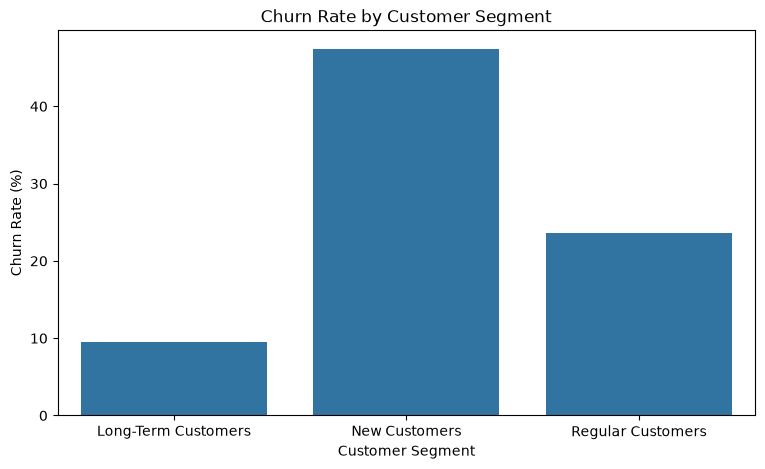

In [4]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_analysis.reset_index(),
    x="CustomerSegment",
    y="Churn_Rate"
)

plt.title("Churn Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")

plt.show()

In [5]:
df["HighMonthlyCharges"] = (
    df["MonthlyCharges"] > df["MonthlyCharges"].median()
).astype(int)

df["MonthToMonth"] = (
    df["Contract"] == "Month-to-month"
).astype(int)

df["NewCustomer"] = (
    df["tenure"] <= 12
).astype(int)

df["RiskScore"] = (
    df["HighMonthlyCharges"] +
    df["MonthToMonth"] +
    df["NewCustomer"]
)

In [6]:
df["RiskCategory"] = pd.cut(
    df["RiskScore"],
    bins=[-1, 1, 2, 3],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print(df["RiskCategory"].value_counts())

RiskCategory
Low Risk       3800
Medium Risk    2431
High Risk       812
Name: count, dtype: int64


In [7]:
risk_analysis = df.groupby(
    "RiskCategory",
    observed=False
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

risk_analysis["Churn_Rate"] = (
    risk_analysis["Churned_Customers"] /
    risk_analysis["Total_Customers"]
) * 100

risk_analysis.round(2)

,Total_Customers,Churned_Customers,Churn_Rate
RiskCategory,,,
Low Risk,3800,331,8.71
Medium Risk,2431,970,39.90
High Risk,812,568,69.95


In [8]:
segment_analysis.to_csv(
    "../reports/customer_segment_analysis.csv"
)

risk_analysis.to_csv(
    "../reports/churn_risk_analysis.csv"
)

print("Customer segmentation reports exported!")

Customer segmentation reports exported!
